# Lightcurve quality and detection-criteria audit

This notebook audits serialized detected sources from `ZTF_sim.py`. It separates the span of positive detections from the span of all stored observations: the former is the relevant check for the detector's 14-day qualifying window, while the latter can include non-detections outside that window.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

QUALITY = Path('results/detection_criteria_sweep/lightcurve_quality.csv')
quality = pd.read_csv(QUALITY)
quality.head()

,file,source_index,z,t_exp,n_positive,n_non_detections,n_bands,bands,duplicate_positive_times,positive_span_days,...,positive_span_exceeds_14_days,all_observation_span_exceeds_14_days,criteria_snr_threshold,criteria_snr_threshold_secondary,criteria_min_detections,criteria_min_detections_primary,criteria_min_time_separation_hours,criteria_min_fade_rate,criteria_min_galactic_lat,band_counts
0,results/detection_criteria_sweep/snr4_snr22_nd...,0,0.02857,60154.698,9,100,2,g;r,0,88.89029,...,True,True,4.0,2.0,2,1,12.0,0.3,0.0,"{""g"": 2, ""r"": 7}"
1,results/detection_criteria_sweep/snr4_snr22_nd...,1,0.06014,58525.968,1,435,1,g,0,0.00000,...,False,True,4.0,2.0,2,1,12.0,0.3,0.0,"{""g"": 1}"
2,results/detection_criteria_sweep/snr4_snr22_nd...,2,0.04193,59464.779,11,220,2,g;r,0,49.94175,...,True,True,4.0,2.0,2,1,12.0,0.3,0.0,"{""g"": 7, ""r"": 4}"
3,results/detection_criteria_sweep/snr4_snr22_nd...,3,0.02556,60691.361,3,74,2,g;r,0,22.00574,...,True,True,4.0,2.0,2,1,12.0,0.3,0.0,"{""g"": 1, ""r"": 2}"
4,results/detection_criteria_sweep/snr4_snr22_nd...,4,0.03360,60263.142,12,109,2,g;r,0,62.72165,...,True,True,4.0,2.0,2,1,12.0,0.3,0.0,"{""g"": 6, ""r"": 6}"


In [2]:
quality[['positive_span_days', 'all_observation_span_days', 'max_positive_gap_days', 'n_positive']].describe(percentiles=[.5, .9, .95, .99]).T

,count,mean,std,min,50%,90%,95%,99%,max
positive_span_days,177919.0,44.470539,34.319166,0.00000,44.90143,90.872240,95.809444,100.818493,104.84413
all_observation_span_days,177919.0,114.709732,20.735751,0.98089,120.35103,132.820622,133.830230,134.897165,138.94900
max_positive_gap_days,177919.0,21.279027,18.117768,0.00000,19.98867,45.931228,55.892464,79.874883,104.72227
n_positive,177919.0,7.917277,9.159565,1.00000,5.00000,18.000000,25.000000,44.000000,228.00000


In [3]:
print('Positive spans over 14 days:', int(quality['positive_span_exceeds_14_days'].sum()))
print('All-observation spans over 14 days:', int(quality['all_observation_span_exceeds_14_days'].sum()))
quality.loc[quality['positive_span_exceeds_14_days']].sort_values('positive_span_days', ascending=False).head(20)

Positive spans over 14 days: 125607
All-observation spans over 14 days: 177821


,file,source_index,z,t_exp,n_positive,n_non_detections,n_bands,bands,duplicate_positive_times,positive_span_days,...,positive_span_exceeds_14_days,all_observation_span_exceeds_14_days,criteria_snr_threshold,criteria_snr_threshold_secondary,criteria_min_detections,criteria_min_detections_primary,criteria_min_time_separation_hours,criteria_min_fade_rate,criteria_min_galactic_lat,band_counts
44942,results/detection_criteria_sweep/snr4_snr24_nd...,4,0.05397,58230.984,35,861,2,g;r,0,104.84413,...,True,True,4.0,4.0,2,1,12.0,0.3,15.0,"{""g"": 27, ""r"": 8}"
60842,results/detection_criteria_sweep/snr4_snr24_nd...,80,0.05315,58231.162,20,573,2,g;r,0,104.84271,...,True,True,4.0,4.0,3,2,3.0,0.0,0.0,"{""g"": 17, ""r"": 3}"
110990,results/detection_criteria_sweep/snr5_snr24_nd...,62,0.05924,60356.487,3,266,1,g,0,104.77905,...,True,True,5.0,4.0,2,2,3.0,0.0,0.0,"{""g"": 3}"
159336,results/detection_criteria_sweep/snr6_snr24_nd...,45,0.05067,58849.230,8,96,1,g,0,104.77588,...,True,True,6.0,4.0,2,1,3.0,0.6,0.0,"{""g"": 8}"
146608,results/detection_criteria_sweep/snr6_snr23_nd...,18,0.05889,58494.142,2,51,1,g,0,104.72227,...,True,True,6.0,3.0,3,1,3.0,0.6,0.0,"{""g"": 2}"
160426,results/detection_criteria_sweep/snr6_snr24_nd...,1,0.04813,58382.458,7,100,2,g;r,0,104.68557,...,True,True,6.0,4.0,2,1,12.0,0.3,15.0,"{""g"": 4, ""r"": 3}"
45930,results/detection_criteria_sweep/snr4_snr24_nd...,216,0.04213,60110.368,28,171,2,g;r,0,104.01222,...,True,True,4.0,4.0,2,2,12.0,0.0,0.0,"{""g"": 13, ""r"": 15}"
63048,results/detection_criteria_sweep/snr4_snr24_nd...,28,0.04585,59751.366,12,189,2,g;r,0,103.91877,...,True,True,4.0,4.0,4,1,12.0,0.0,15.0,"{""g"": 6, ""r"": 6}"
45016,results/detection_criteria_sweep/snr4_snr24_nd...,56,0.04703,59737.452,18,115,2,g;r,0,103.90893,...,True,True,4.0,4.0,2,1,12.0,0.0,0.0,"{""g"": 11, ""r"": 7}"
56875,results/detection_criteria_sweep/snr4_snr24_nd...,14,0.04523,60918.184,14,396,2,g;r,0,103.90308,...,True,True,4.0,4.0,3,2,3.0,0.3,0.0,"{""g"": 10, ""r"": 4}"


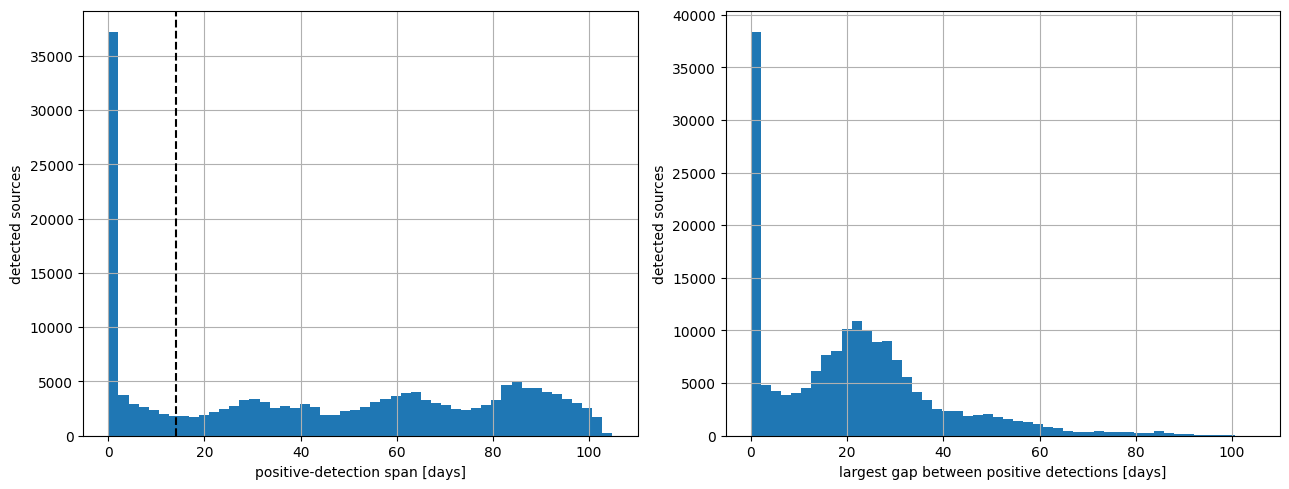

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
quality['positive_span_days'].hist(ax=axes[0], bins=50)
axes[0].axvline(14, color='black', linestyle='--')
axes[0].set_xlabel('positive-detection span [days]')
quality['max_positive_gap_days'].hist(ax=axes[1], bins=50)
axes[1].set_xlabel('largest gap between positive detections [days]')
for axis in axes: axis.set_ylabel('detected sources')
fig.tight_layout()

## Criteria sweep comparison

The sweep output directories encode SNR threshold, minimum detections, and maximum timespan. Rate-limit summaries can be compared against the quality distributions to identify criteria combinations that change the result for physical reasons versus timing or cadence artifacts.

In [7]:
import re
from pathlib import Path

rows = []
for path in Path('results/detection_criteria_sweep').glob('*/Bu2026Fixed/*.json'):
    match = re.search(r'snr([0-9.]+)_ndet(\d+)_span([0-9.]+)d', str(path))
    if match:
        rows.append({'file': str(path), 'snr_threshold': float(match.group(1)), 'min_detections': int(match.group(2)), 'max_timespan_days': float(match.group(3))})
criteria = pd.DataFrame(rows)
criteria

""


In [8]:
import json
import re
import numpy as np
from matplotlib.lines import Line2D

SWEEP_ROOT = Path('results/detection_criteria_sweep')
FOLDER_PATTERN = re.compile(
    r'^snr(?P<snr>[0-9.]+)_snr2(?P<snr_secondary>[0-9.]+)'
    r'_ndet(?P<min_detections>\d+)_ndet1(?P<min_detections_primary>\d+)'
    r'_span(?P<max_timespan_days>[0-9.]+)d_sep(?P<min_time_separation_hours>[0-9.]+)h'
    r'_fade(?P<min_fade_rate>[0-9.]+)_b(?P<min_galactic_lat>[0-9.]+)$'
)


def parse_criteria_folder(folder_name):
    match = FOLDER_PATTERN.match(folder_name)
    if match is None:
        return None
    values = match.groupdict()
    float_fields = {
        'snr', 'snr_secondary', 'max_timespan_days',
        'min_time_separation_hours', 'min_fade_rate', 'min_galactic_lat',
    }
    return {
        key: (float(value) if key in float_fields else int(value))
        for key, value in values.items()
    }


index_rows = []
for result_path in sorted(SWEEP_ROOT.glob('*/Bu2026Fixed/*.json')):
    if result_path.name.endswith('.metadata.json'):
        continue
    criteria = parse_criteria_folder(result_path.parent.parent.name)
    if criteria is None:
        continue
    with result_path.open() as handle:
        result = json.load(handle)
    index_rows.append({
        **criteria,
        'folder': result_path.parent.parent.name,
        'file': result_path,
        'n_detected': len(result.get('detected_sources', [])),
    })

sweep_index = pd.DataFrame(index_rows)
if sweep_index.empty:
    raise ValueError(f'No sweep results found under {SWEEP_ROOT}')
sweep_index.head()

,snr,snr_secondary,min_detections,min_detections_primary,max_timespan_days,min_time_separation_hours,min_fade_rate,min_galactic_lat,folder,file,n_detected
0,4.0,2.0,2,1,14.0,12.0,0.3,0.0,snr4_snr22_ndet2_ndet11_span14d_sep12h_fade0.3_b0,results/detection_criteria_sweep/snr4_snr22_nd...,14
1,4.0,2.0,2,1,14.0,12.0,0.3,15.0,snr4_snr22_ndet2_ndet11_span14d_sep12h_fade0.3...,results/detection_criteria_sweep/snr4_snr22_nd...,15
2,4.0,2.0,2,1,14.0,12.0,0.6,0.0,snr4_snr22_ndet2_ndet11_span14d_sep12h_fade0.6_b0,results/detection_criteria_sweep/snr4_snr22_nd...,15
3,4.0,2.0,2,1,14.0,12.0,0.6,15.0,snr4_snr22_ndet2_ndet11_span14d_sep12h_fade0.6...,results/detection_criteria_sweep/snr4_snr22_nd...,14
4,4.0,2.0,2,1,14.0,12.0,0.0,0.0,snr4_snr22_ndet2_ndet11_span14d_sep12h_fade0_b0,results/detection_criteria_sweep/snr4_snr22_nd...,172


## Sweep-aware lightcurve plots

The cells below decode every criterion from each result folder. The summary plot shows how the number of detected sources changes with each imposed parameter. The lightcurve helper then plots stored positive detections and non-detections for selected criterion combinations, with the full folder configuration in each panel title.

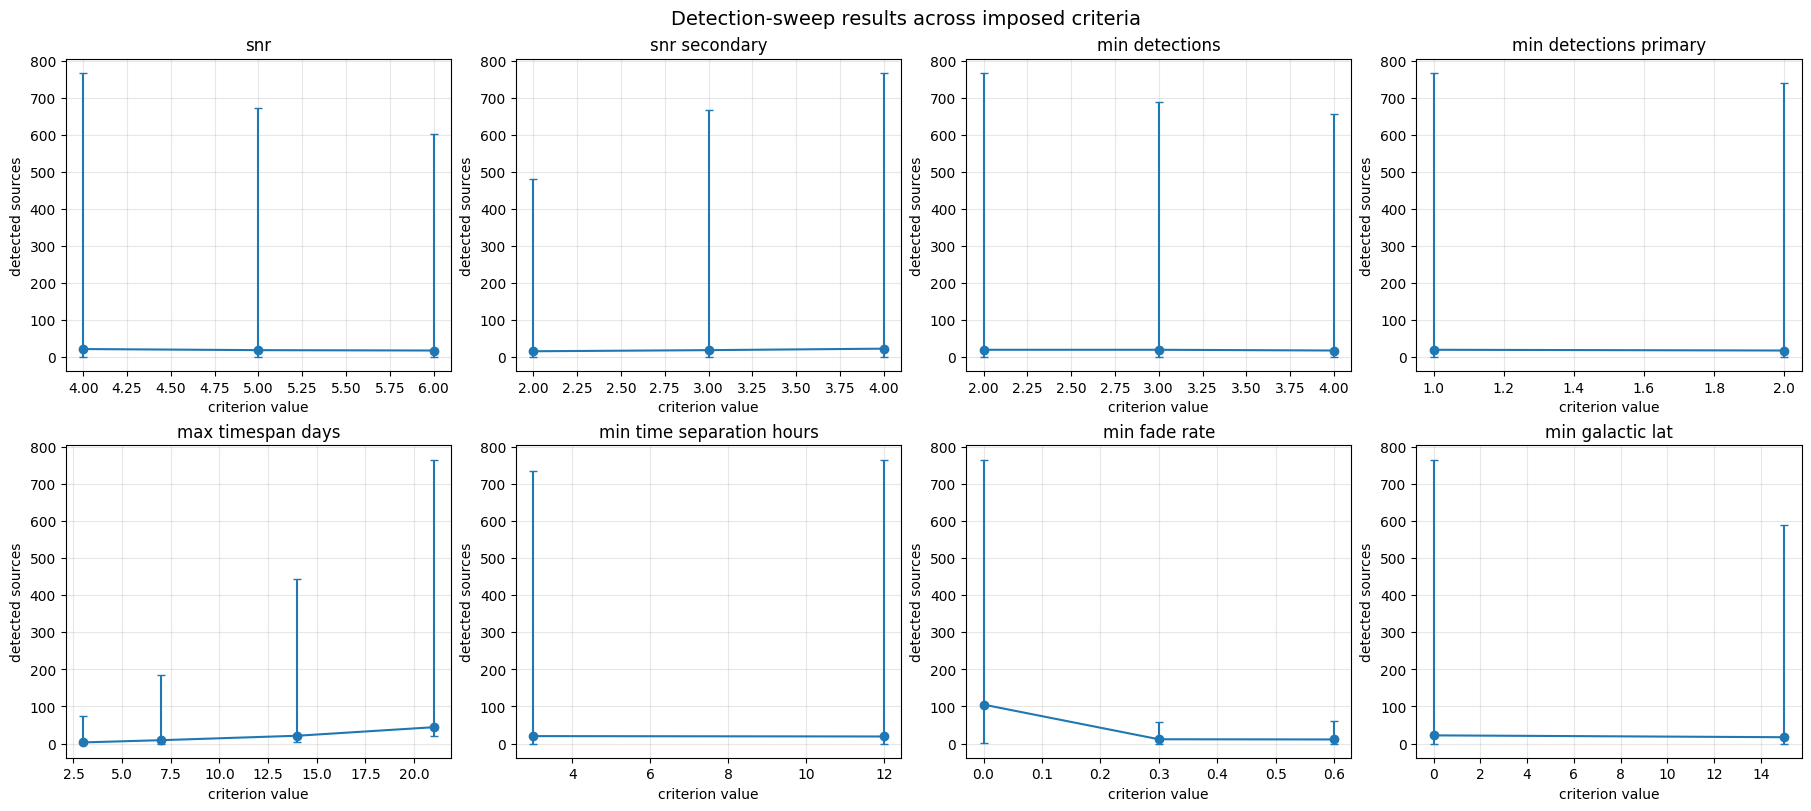

count  \
snr snr_secondary min_detections min_detections_primary max_timespan_days min_time_separation_hours min_fade_rate min_galactic_lat          
4.0 4.0           2              1                      21.0              12.0                      0.0           0.0                   1   
                                 2                      21.0              12.0                      0.0           0.0                   1   
                                                                          3.0                       0.0           0.0                   1   
                                 1                      21.0              3.0                       0.0           0.0                   1   
                  3              1                      21.0              12.0                      0.0           0.0                   1   
                                 2                      21.0              3.0                       0.0           0.0                   1   
5.0 4.0           2              1                      21.0              12.0                      0.0           0.0                   1   
4.0 4.0           3              2                      21.0              12.0                      0.0           0.0                   1   
    3.0           3              1                      21.0              3.0                       0.0           0.0                   1   
5.0 4.0           3              1                      21.0              12.0                      0.0           0.0                   1   

                                                                                                                                     mean  \
snr snr_secondary min_detections min_detections_primary max_timespan_days min_time_separation_hours min_fade_rate min_galactic_lat          
4.0 4.0           2              1                      21.0              12.0                      0.0           0.0               766.0   
                                 2                      21.0              12.0                      0.0           0.0               740.0   
                                                                          3.0                       0.0           0.0               736.0   
                                 1                      21.0              3.0                       0.0           0.0               712.0   
                  3              1                      21.0              12.0                      0.0           0.0               689.0   
                                 2                      21.0              3.0                       0.0           0.0               678.0   
5.0 4.0           2              1                      21.0              12.0                      0.0           0.0               671.0   
4.0 4.0           3              2                      21.0              12.0                      0.0           0.0               668.0   
    3.0           3              1                      21.0              3.0                       0.0           0.0               666.0   
5.0 4.0           3              1                      21.0              12.0                      0.0           0.0               659.0   

                                                                                                                                    median  
snr snr_secondary min_detections min_detections_primary max_timespan_days min_time_separation_hours min_fade_rate min_galactic_lat          
4.0 4.0           2              1                      21.0              12.0                      0.0           0.0                766.0  
                                 2                      21.0              12.0                      0.0           0.0                740.0  
                                                                          3.0                       0.0           0.0                736.0  
                                 1       

In [9]:
criterion_columns = [
    'snr', 'snr_secondary', 'min_detections', 'min_detections_primary',
    'max_timespan_days', 'min_time_separation_hours', 'min_fade_rate',
    'min_galactic_lat',
]

# A compact overview: one panel per criterion, with all other criteria retained.
fig, axes = plt.subplots(2, 4, figsize=(18, 8), constrained_layout=True)
for axis, column in zip(axes.flat, criterion_columns):
    grouped = (
        sweep_index.groupby(column, as_index=False)['n_detected']
        .agg(['mean', 'median', 'min', 'max', 'count'])
        .reset_index()
        .sort_values(column)
    )
    axis.errorbar(
        grouped[column],
        grouped['median'],
        yerr=[grouped['median'] - grouped['min'], grouped['max'] - grouped['median']],
        fmt='o-', capsize=3, color='C0',
    )
    axis.set_title(column.replace('_', ' '))
    axis.set_xlabel('criterion value')
    axis.set_ylabel('detected sources')
    axis.grid(alpha=0.3)

fig.suptitle('Detection-sweep results across imposed criteria', fontsize=14)
plt.show()

sweep_index.groupby(criterion_columns, dropna=False)['n_detected'].agg(['count', 'mean', 'median']).sort_values('median', ascending=False).head(10)

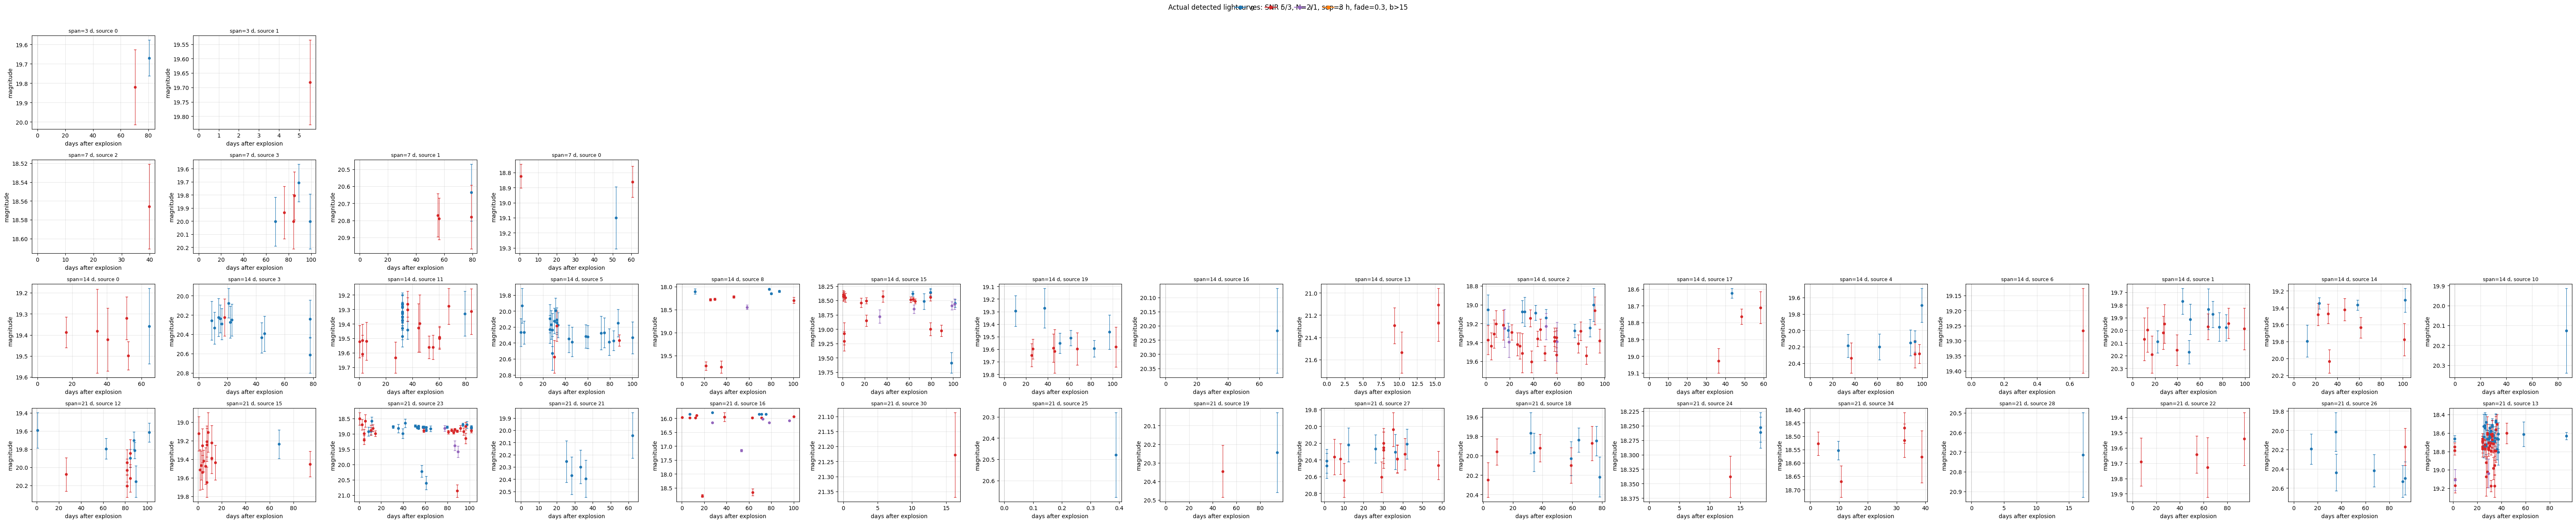

In [12]:
# Plot the actual serialized lightcurves for a controlled criteria slice.
# This varies only max_timespan_days; change the filters to inspect another slice.
BAND_COLORS = {'g': 'tab:blue', 'r': 'tab:red', 'i': 'tab:purple', 'z': 'tab:orange'}

controlled = sweep_index[
    (sweep_index.snr == 5.0)
    & (sweep_index.snr_secondary == 3.0)
    & (sweep_index.min_detections == 2)
    & (sweep_index.min_detections_primary == 1)
    & (sweep_index.min_time_separation_hours == 3.0)
    & (sweep_index.min_fade_rate == 0.3)
    & (sweep_index.min_galactic_lat == 15.0)
].sort_values('max_timespan_days')

n_examples = 16
fig, axes = plt.subplots(
    len(controlled), n_examples,
    figsize=(4 * n_examples, 3.2 * max(len(controlled), 1)),
    squeeze=False,
    sharex=False,
    sharey=False,
)

for row_number, (_, criteria) in enumerate(controlled.iterrows()):
    with Path(criteria.file).open() as handle:
        result = json.load(handle)
    sources = result.get('detected_sources', [])
    rng = np.random.default_rng(42 + row_number)
    selected = rng.choice(len(sources), size=min(n_examples, len(sources)), replace=False)

    for column_number in range(n_examples):
        axis = axes[row_number, column_number]
        if column_number >= len(selected):
            axis.set_visible(False)
            continue
        source = sources[int(selected[column_number])]
        t_exp = float(source.get('t_exp', 0.0))

        times = np.asarray(source.get('photometry_times', []), dtype=float) - t_exp
        mags = np.asarray(source.get('photometry_mags', []), dtype=float)
        errors = np.asarray(source.get('photometry_errs', []), dtype=float)
        bands = np.asarray(source.get('photometry_bands', []), dtype=str)

        for band, color in BAND_COLORS.items():
            mask = bands == band
            if mask.any():
                axis.errorbar(
                    times[mask], mags[mask], yerr=errors[mask],
                    fmt='o', color=color, markersize=4, linewidth=0.8,
                    capsize=2, label=band,
                )

        axis.invert_yaxis()
        axis.axvline(0, color='0.5', linestyle=':', linewidth=0.8)
        axis.set_title(
            f"span={criteria.max_timespan_days:g} d, "
            f"source {int(selected[column_number])}",
            fontsize=9,
        )
        axis.set_xlabel('days after explosion')
        axis.set_ylabel('magnitude')
        axis.grid(alpha=0.3)

fig.suptitle(
    'Actual detected lightcurves: SNR 5/3, N=2/1, sep=3 h, fade=0.3, b>15',
    y=1.01,
)
handles = [Line2D([0], [0], color=color, marker='o', label=band) for band, color in BAND_COLORS.items()]
fig.legend(handles=handles, loc='upper center', ncol=len(handles), frameon=False)
fig.tight_layout()
plt.show()